Week 5 - Additional Models


*   Try Decision Tree and Random Forest regressors.
*   Compare their test R^2 against baseline.
*   Document model behavior (strengths/weaknesses)
*   **Deliverable:** 04_model_comparison.ipynb





In [11]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

drive.mount('/content/drive')
DATA_DIR = "/content/drive/MyDrive/output"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
cleaned = pd.read_csv(os.path.join(DATA_DIR, "cleaned_data.csv"))
train = cleaned[cleaned["split"] == "train"].copy()
test = cleaned[cleaned["split"] == "test"].copy()

target = "ClosePrice"
feature_cols = [c for c in train.columns if c not in [target, "CloseDate", "split"]]

X_train, y_train = train[feature_cols], train[target]
X_test, y_test = test[feature_cols], test[target]

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Features:", feature_cols)

Train: (265372, 7)  Test: (11178, 7)
Features: ['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet', 'YearBuilt', 'City_freq', 'PostalCode_freq']


In [14]:
def evaluate(model, name):
    train_preds = model.predict(X_train)
    test_preds = model.predict(X_test)
    return {
        "model": name,
        "train_R2": r2_score(y_train, train_preds),
        "test_R2": r2_score(y_test, test_preds),
        "test_MAE": mean_absolute_error(y_test, test_preds),
        "test_RMSE": np.sqrt(mean_squared_error(y_test, test_preds)),
    }, test_preds


In [15]:
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_results, lr_preds = evaluate(lr, "Linear Regression (baseline)")
print(lr_results)


{'model': 'Linear Regression (baseline)', 'train_R2': 0.4919584936895943, 'test_R2': 0.47999556156641265, 'test_MAE': 515188.74809245754, 'test_RMSE': np.float64(937892.6865163067)}


In [16]:
depths = [2, 4, 6, 8, 10, 15, 20, None]
tree_rows = []

for d in depths:
    tree = DecisionTreeRegressor(max_depth=d, random_state=42)
    tree.fit(X_train, y_train)
    tr_r2 = r2_score(y_train, tree.predict(X_train))
    te_r2 = r2_score(y_test, tree.predict(X_test))
    tree_rows.append({"max_depth": "None" if d is None else d, "train_R2": tr_r2, "test_R2": te_r2})
    print(f"max_depth={str(d):>4} | train R2 = {tr_r2:.4f} | test R2 = {te_r2:.4f}")

tree_sweep = pd.DataFrame(tree_rows)
tree_sweep


max_depth=   2 | train R2 = 0.3757 | test R2 = 0.3763
max_depth=   4 | train R2 = 0.4752 | test R2 = 0.4660
max_depth=   6 | train R2 = 0.5344 | test R2 = 0.5258
max_depth=   8 | train R2 = 0.5856 | test R2 = 0.5431
max_depth=  10 | train R2 = 0.6509 | test R2 = 0.5637
max_depth=  15 | train R2 = 0.8230 | test R2 = 0.5692
max_depth=  20 | train R2 = 0.9452 | test R2 = 0.5844
max_depth=None | train R2 = 0.9988 | test R2 = 0.5565


,max_depth,train_R2,test_R2
0,2,0.375723,0.376267
1,4,0.475236,0.465977
2,6,0.534358,0.525780
3,8,0.585602,0.543129
4,10,0.650903,0.563720
5,15,0.823010,0.569215
6,20,0.945166,0.584412
7,None,0.998835,0.556451


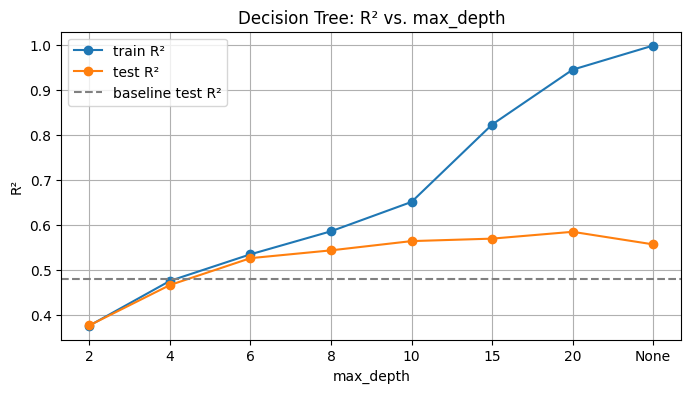

In [17]:
plt.figure(figsize=(8, 4))
plt.plot(tree_sweep["max_depth"].astype(str), tree_sweep["train_R2"], marker="o", label="train R²")
plt.plot(tree_sweep["max_depth"].astype(str), tree_sweep["test_R2"], marker="o", label="test R²")
plt.axhline(lr_results["test_R2"], color="gray", linestyle="--", label="baseline test R²")
plt.title("Decision Tree: R² vs. max_depth")
plt.xlabel("max_depth")
plt.ylabel("R²")
plt.legend()
plt.grid(True)
plt.show()


In [18]:
best_depth_label = tree_sweep.loc[tree_sweep["test_R2"].idxmax(), "max_depth"]
best_depth = None if best_depth_label == "None" else int(best_depth_label)
print("Best max_depth:", best_depth)

dt = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
dt.fit(X_train, y_train)
dt_results, dt_preds = evaluate(dt, f"Decision Tree (max_depth={best_depth})")
print(dt_results)


Best max_depth: 20
{'model': 'Decision Tree (max_depth=20)', 'train_R2': 0.9451663893911487, 'test_R2': 0.5844115392400433, 'test_MAE': 327849.78689019656, 'test_RMSE': np.float64(838458.0993547962)}


In [19]:
start = time.time()
rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
print(f"Trained in {time.time() - start:.0f} seconds")

rf_results, rf_preds = evaluate(rf, "Random Forest (100 trees)")
print(rf_results)


Trained in 129 seconds
{'model': 'Random Forest (100 trees)', 'train_R2': 0.8725278503666806, 'test_R2': 0.7521393577585558, 'test_MAE': 262836.0378277512, 'test_RMSE': np.float64(647520.3315499077)}


In [20]:
comparison = pd.DataFrame([lr_results, dt_results, rf_results])
comparison["R2_gap (train - test)"] = comparison["train_R2"] - comparison["test_R2"]
comparison["test_R2_vs_baseline"] = comparison["test_R2"] - lr_results["test_R2"]

display(comparison.round(4))

os.makedirs(DATA_DIR, exist_ok=True)
comparison.to_csv(os.path.join(DATA_DIR, "model_comparison.csv"), index=False)


,model,train_R2,test_R2,test_MAE,test_RMSE,R2_gap (train - test),test_R2_vs_baseline
0,Linear Regression (baseline),0.4920,0.4800,515188.7481,937892.6865,0.0120,0.0000
1,Decision Tree (max_depth=20),0.9452,0.5844,327849.7869,838458.0994,0.3608,0.1044
2,Random Forest (100 trees),0.8725,0.7521,262836.0378,647520.3315,0.1204,0.2721


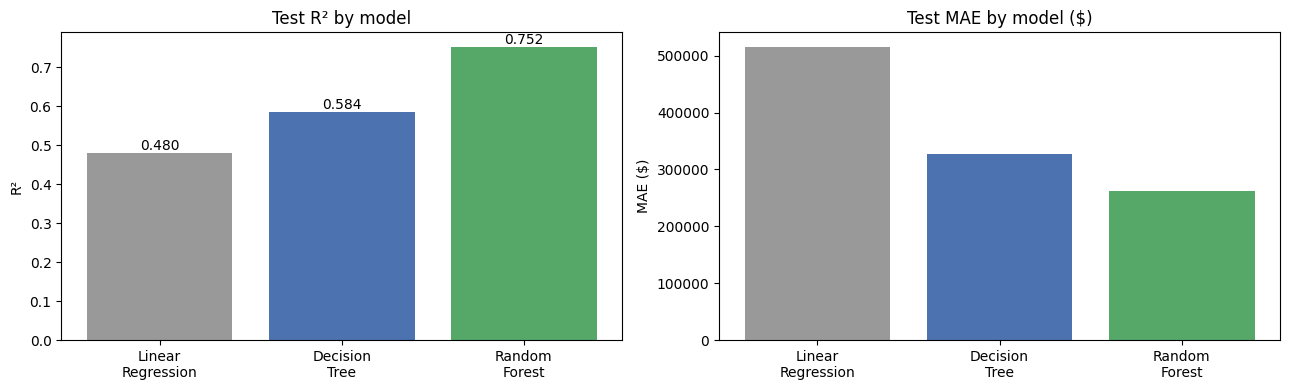

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

names = ["Linear\nRegression", "Decision\nTree", "Random\nForest"]
axes[0].bar(names, comparison["test_R2"], color=["#999999", "#4C72B0", "#55A868"])
axes[0].set_title("Test R² by model")
axes[0].set_ylabel("R²")
for i, v in enumerate(comparison["test_R2"]):
    axes[0].text(i, v, f"{v:.3f}", ha="center", va="bottom")

axes[1].bar(names, comparison["test_MAE"], color=["#999999", "#4C72B0", "#55A868"])
axes[1].set_title("Test MAE by model ($)")
axes[1].set_ylabel("MAE ($)")

plt.tight_layout()
plt.show()


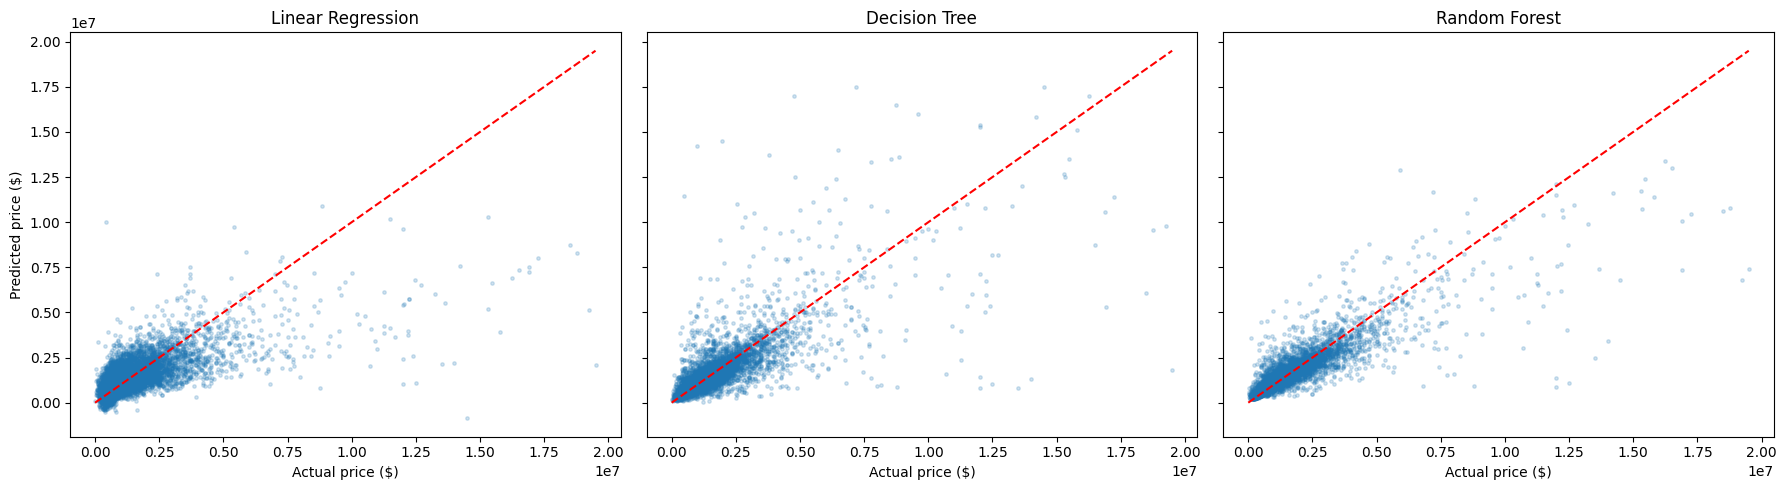

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
all_preds = [("Linear Regression", lr_preds), ("Decision Tree", dt_preds), ("Random Forest", rf_preds)]
lim = max(y_test.max(), 1)

for ax, (name, p) in zip(axes, all_preds):
    ax.scatter(y_test, p, alpha=0.2, s=6)
    ax.plot([0, lim], [0, lim], color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Actual price ($)")
axes[0].set_ylabel("Predicted price ($)")
plt.tight_layout()
plt.show()


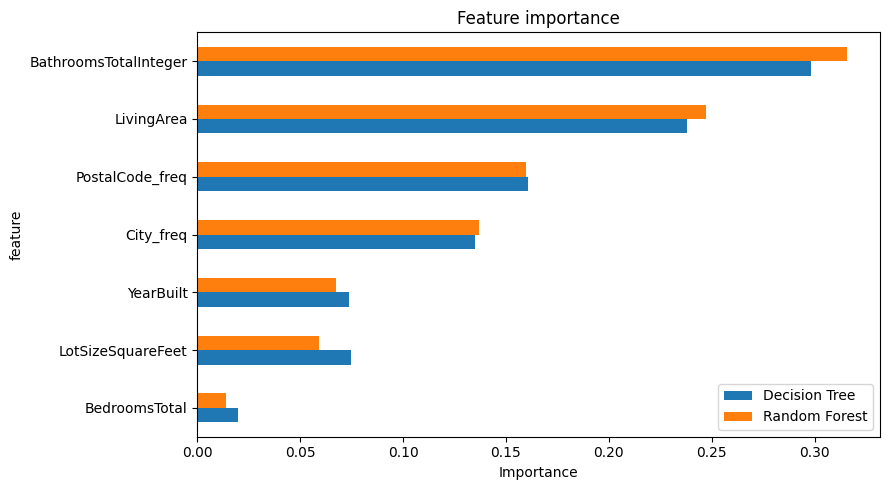

,feature,Decision Tree,Random Forest
2,BathroomsTotalInteger,0.2983,0.3160
0,LivingArea,0.2379,0.2474
6,PostalCode_freq,0.1607,0.1597
5,City_freq,0.1351,0.1370
4,YearBuilt,0.0737,0.0673
3,LotSizeSquareFeet,0.0745,0.0589
1,BedroomsTotal,0.0197,0.0137


In [23]:
importances = pd.DataFrame({
    "feature": feature_cols,
    "Decision Tree": dt.feature_importances_,
    "Random Forest": rf.feature_importances_,
}).sort_values("Random Forest", ascending=True)

importances.plot(x="feature", kind="barh", figsize=(9, 5))
plt.title("Feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

importances.sort_values("Random Forest", ascending=False).round(4)


**Model Comparison** After comparing three models on the same train/test split, I found that Random Forest did the best with a test R^2 of 0.752, then Decision Tree at 0.584, and the Linear Regression baseline at 0.480. The Random Forest improved on the baseline by 0.272 R^2, and the Decision Tree by 0.104. The same goes for the MAE: about \$515K for Linear Regression, \$328K for the Decision Tree, and \$263K for the Random Forest, so the Random Forest cut the average error roughly in half compared to the baseline.

**Overfitting** The gap between train and test R^2 was very different across the models. Linear Regression barely overfit, but it also couldn't learn much. The Decision Tree overfit badly. In the depth sweep, train R^2 kept climbing as max_depth increased, while test R^2 flattened out around depths 10 to 20 and then dropped to 0.556 with no limit, which means the unlimited tree was memorizing the training data. The Random Forest also overfit some, but much less than the single tree, since averaging 100 trees smooths out the noise.

**Strengths**
*   **Linear Regression**: Very fast and simple. Coefficients are easy to interpret. Barely overfit.
*   **Decision Tree**: Easy to follow as a set of if/else rules. Captures non-linear patterns and feature interactions without scaling. Improved test R^2 to 0.584 over the baseline.
*   **Random Forest**: Best accuracy. Much less overfit than a single tree because it averages many trees. Handles non-linear patterns and gives feature importance.

**Weaknesses**
*   **Linear Regression**: Only learns straight-line relationships, so it missed the way price changes with location and size. Under-predicted expensive homes and produced negative prices. Affected by correlated features like bedrooms and living area. Lowest accuracy of the three.
*   **Decision Tree**: Overfit heavily and was very sensitive to the max_depth setting. Predictions were noisy, with big misses in both directions. Unstable, since a small change in the data can change the whole tree.
*   **Random Forest**: Slower to train and harder to explain than one tree. Still overfit somewhat. Can't predict above the prices it saw in training, so it still under-predicted the most expensive homes.



